In [11]:
# OpenCV library
import cv2
import matplotlib.pyplot as plt
import numpy as np

Images successfully loaded and converted to grayscale.


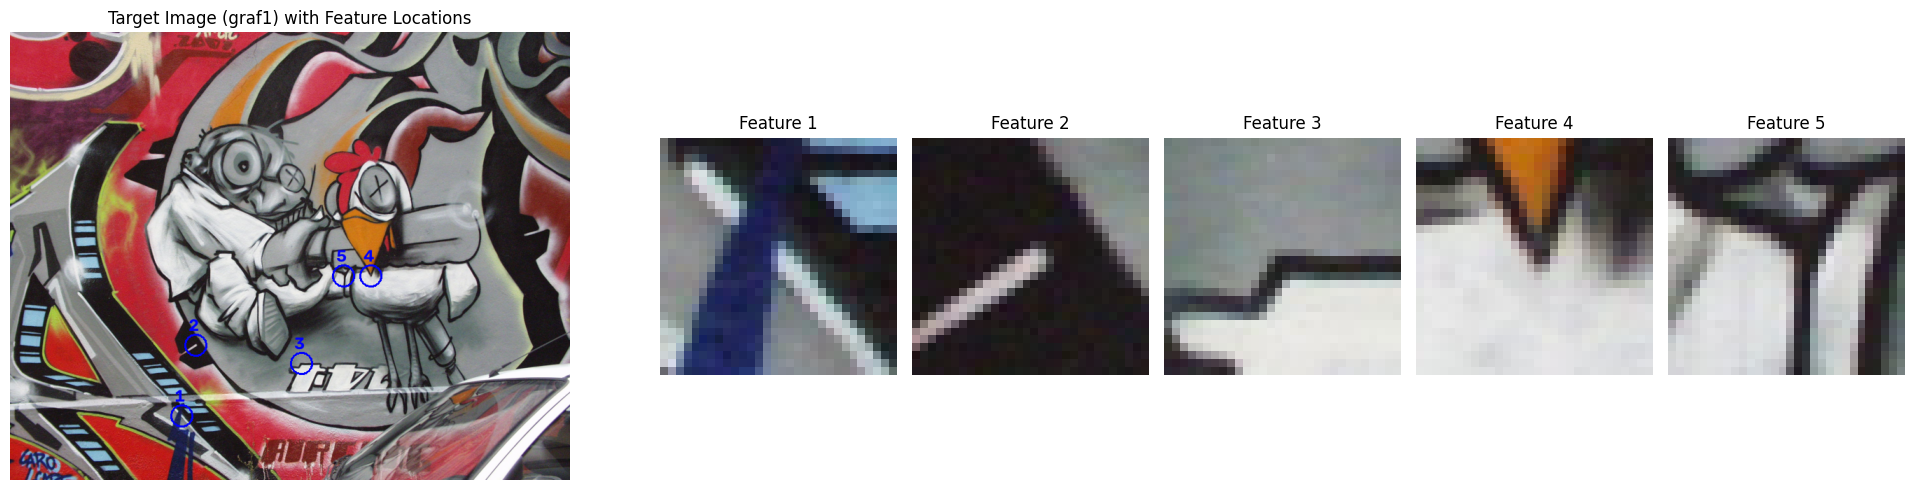

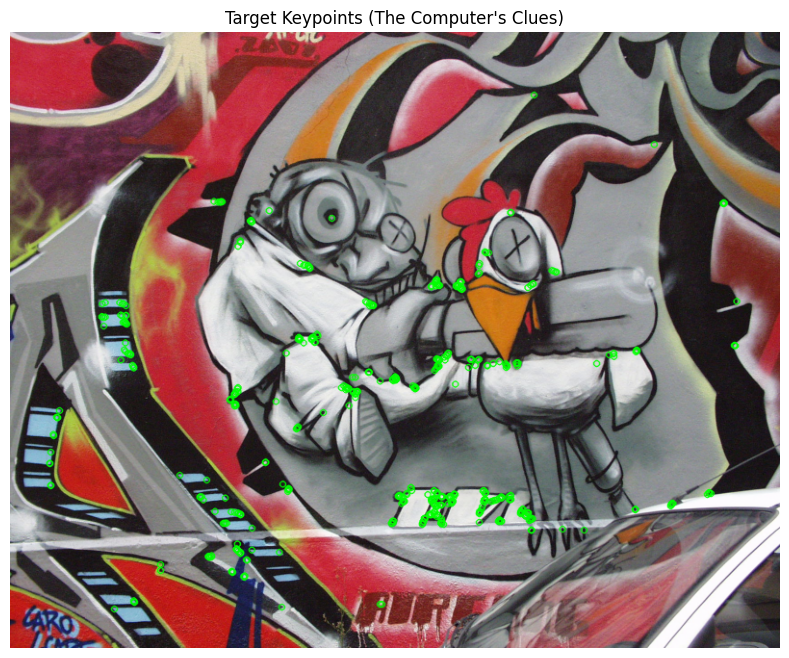

Total features matched (raw cross-check): 172


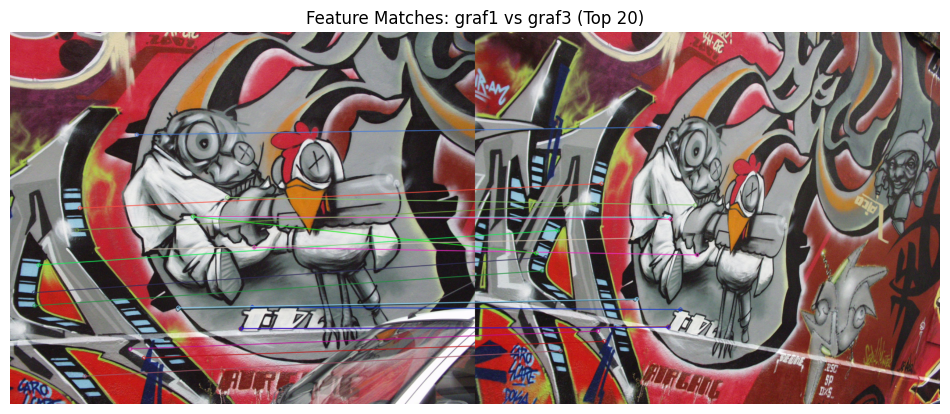

In [12]:
# Helper function to display images properly in Colab
def show_img(title, img):
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

# Step 1: Load and Prepare Images
img_target = cv2.imread('graf1.png')
img_scene = cv2.imread('graf3.png')

if img_target is None or img_scene is None:
    print("Error: Could not load images. Ensure graf1.png and graf3.png are in the current directory.")
else:
    gray_target = cv2.cvtColor(img_target, cv2.COLOR_BGR2GRAY)
    gray_scene = cv2.cvtColor(img_scene, cv2.COLOR_BGR2GRAY)
    print("Images successfully loaded and converted to grayscale.")

# Step 2: Extract Features using ORB & Inspect Patches
orb = cv2.ORB_create(nfeatures=500)

kp_target, des_target = orb.detectAndCompute(gray_target, None)
kp_scene, des_scene = orb.detectAndCompute(gray_scene, None)

# Setup figure with 6 subplots (1 main image + 5 zoomed 30x30 feature patches)
fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]})
img_target_annotated = img_target.copy()
offset = 15  # 15 pixels in every direction creates a 30x30 patch

for i in range(5):
    kp = kp_target[i]
    x, y = int(kp.pt[0]), int(kp.pt[1])

    # Draw numbered blue circle on the main image
    cv2.circle(img_target_annotated, (x, y), offset, (255, 0, 0), 2)
    cv2.putText(img_target_annotated, str(i + 1), (x - 10, y - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    # Crop the pixel patch safely within image bounds
    patch = img_target[max(0, y - offset):min(img_target.shape[0], y + offset),
                       max(0, x - offset):min(img_target.shape[1], x + offset)]

    axes[i + 1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i + 1].set_title(f"Feature {i + 1}")
    axes[i + 1].axis('off')

axes[0].imshow(cv2.cvtColor(img_target_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Target Image (graf1) with Feature Locations")
axes[0].axis('off')
plt.tight_layout()
plt.show()

# Visualize all keypoints found on graf1
img_target_kp = cv2.drawKeypoints(img_target, kp_target, None, color=(0, 255, 0), flags=0)
show_img("Target Keypoints (The Computer's Clues)", img_target_kp)

# Step 3 & 4: Match Features and Analyze Results
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des_target, des_scene)
matches = sorted(matches, key=lambda x: x.distance)

print(f"Total features matched (raw cross-check): {len(matches)}")

# Draw the top 20 best matches
img_matches = cv2.drawMatches(
    img_target, kp_target,
    img_scene, kp_scene,
    matches[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show_img("Feature Matches: graf1 vs graf3 (Top 20)", img_matches)

## Reflection & Discussion

### 1. Feature Effectiveness: Which feature was the most useful for finding the target quickly? Why did it work so well?
High-contrast character outlines and sharp intersections: The distinct black-and-white edges around the cartoon character's eyes, beak/nose, and the sharp corners of the bold graffiti lettering worked best. Because these areas have strong intensity gradients in multiple directions (true corners rather than flat lines), ORB's FAST detector and rBRIEF descriptor generated unique binary signatures that matched reliably between graf1.png and graf3.png.

### 2. Ambiguous Features: Did any feature accidentally match the wrong object?
Repetitive textures and parallel paint strokes: Yes, keypoints located along repetitive shading lines, spray-paint speckles, or long straight edges of the graffiti borders occasionally mismatched. Because a small 30×30 patch along a straight line or uniform cross-hatching looks nearly identical to neighboring patches, the Hamming distance matcher sometimes paired them with the wrong section of the wall. (Applying Lowe's ratio test with knnMatch(..., k=2)—as you did in your notebook—helps filter out most of these ambiguous matches.)

### Robustness Challenge: If the image was rotated or the lighting was different, would the features still work?
Perspective & Scale (graf1 vs. graf3): graf3.png introduces a strong viewpoint/perspective warp (camera angle tilt) rather than a simple 2D rotation. While ORB's image pyramid handles moderate scale changes, extreme perspective skew distorts the local pixel neighborhoods around corners—causing many keypoints to drop off compared to a front-facing view, leaving primarily the strongest, highest-contrast corners to carry the match.